# 03 FMA classical baselines: NB, logistic regression, decision tree, KNN and random forest with stratified 5-fold CV

In [1]:
import sys; sys.path.append('..')
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.config import FIGURES, RESULTS, SEED
from src.data import load_fma, fma_xy
from src.evaluate import evaluate, plot_confusion, save_result

fma = load_fma()
X_train, y_train = fma_xy(fma, "training")
X_val, y_val = fma_xy(fma, "validation")
X_test, y_test = fma_xy(fma, "test")
X_train.shape, X_val.shape, X_test.shape

((6400, 518), (800, 518), (800, 518))

## 1. Models and grids

Every model is `Pipeline(StandardScaler, model)`, so the scaler is fitted inside each CV fold and never sees the held-out fold. Grids step in orders of magnitude; the first parameter listed for each model is the one plotted in its validation curve.

In [2]:
models = {
    "naive_bayes": (GaussianNB(), {"var_smoothing": np.logspace(-9, 0, 10)}),
    "logistic_regression": (LogisticRegression(max_iter=2000, random_state=SEED),
                            {"C": np.logspace(-4, 2, 7)}),
    "decision_tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": [3, 5, 10, 20, None], "min_samples_leaf": [1, 5, 20, 50],
                       "criterion": ["gini", "entropy"]}),
    "knn": (KNeighborsClassifier(), {"n_neighbors": [1, 3, 10, 30, 100], "weights": ["uniform", "distance"]}),
    "random_forest": (RandomForestClassifier(random_state=SEED),
                      {"max_depth": [5, 10, 20, None], "n_estimators": [100, 300],
                       "max_features": ["sqrt", "log2"]}),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

## 2. Tuning on the training split

In [3]:
searches = {}
for name, (model, grid) in models.items():
    t = time.perf_counter()
    gs = GridSearchCV(Pipeline([("scale", StandardScaler()), ("model", model)]),
                      {f"model__{k}": v for k, v in grid.items()},
                      scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True)
    searches[name] = gs.fit(X_train, y_train)
    print(f"{name:20s} CV macro-F1 {gs.best_score_:.4f}  {time.perf_counter() - t:5.0f}s  {gs.best_params_}")

naive_bayes          CV macro-F1 0.3791     12s  {'model__var_smoothing': np.float64(0.1)}


logistic_regression  CV macro-F1 0.5758    109s  {'model__C': np.float64(0.01)}


decision_tree        CV macro-F1 0.4091     76s  {'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 50}


knn                  CV macro-F1 0.4639     10s  {'model__n_neighbors': 3, 'model__weights': 'distance'}


random_forest        CV macro-F1 0.5620    113s  {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__n_estimators': 300}


## 3. Validation curves

Training vs CV macro-F1 across each model's main hyperparameter, with the other hyperparameters held at their best values. A wide gap means overfitting; both curves low means underfitting.

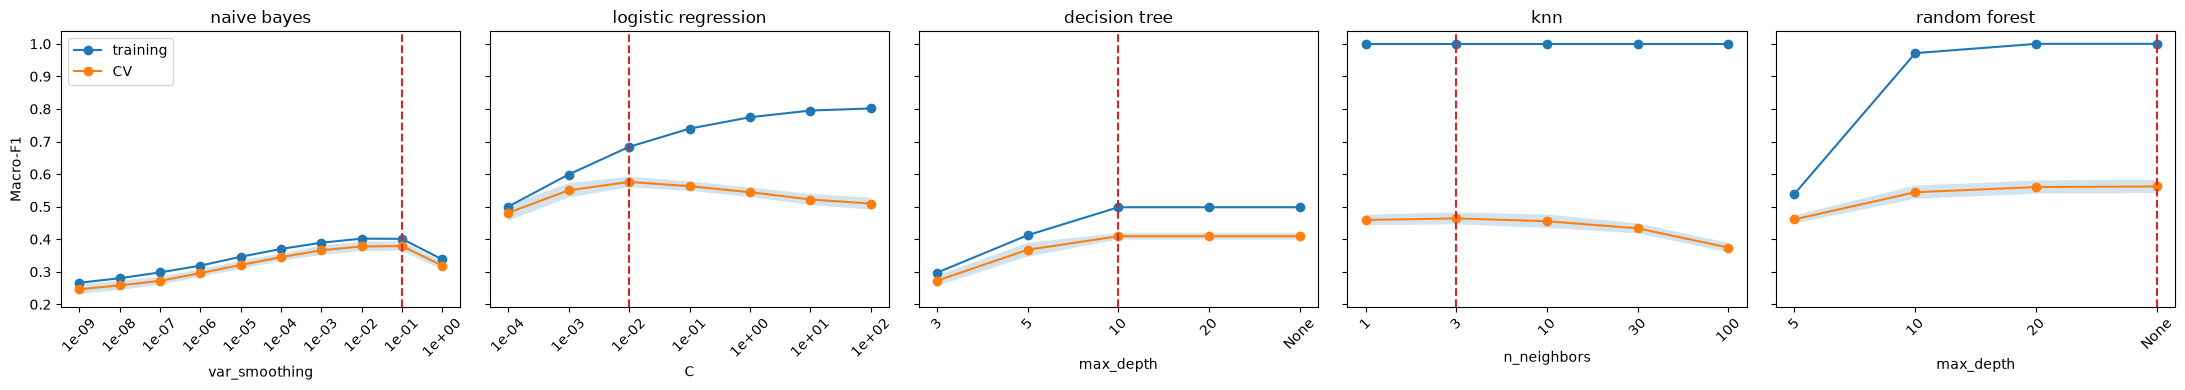

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, (name, gs) in zip(axes, searches.items()):
    main = next(iter(models[name][1]))
    res = pd.DataFrame(gs.cv_results_)
    # Keep only the rows where every other hyperparameter equals its best value.
    keep = np.ones(len(res), bool)
    for p, v in gs.best_params_.items():
        if p != f"model__{main}":
            keep &= res[f"param_{p}"].astype(str) == str(v)
    res = res[keep]
    x = range(len(res))  # categorical x axis: handles log-spaced grids and None alike
    ax.plot(x, res["mean_train_score"], "o-", label="training")
    ax.plot(x, res["mean_test_score"], "o-", label="CV")
    ax.fill_between(x, res["mean_test_score"] - res["std_test_score"],
                    res["mean_test_score"] + res["std_test_score"], alpha=0.2)
    labels = [f"{v:.0e}" if isinstance(v, float) else str(v) for v in res[f"param_model__{main}"]]
    ax.set_xticks(x, labels, rotation=45)
    ax.axvline(list(res[f"param_model__{main}"]).index(gs.best_params_[f"model__{main}"]), color="tab:red", ls="--")
    ax.set(title=name.replace("_", " "), xlabel=main)
axes[0].set_ylabel("Macro-F1")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "fma_baselines_validation_curves.png", dpi=200)

## 4. Validation, then test (once)

`GridSearchCV` has already refitted the best version of each model on the full training split. The model to discuss as best is chosen on validation, never on test.

In [5]:
rows, preds = [], {}
for name, gs in searches.items():
    labels = gs.classes_
    params = {k.removeprefix("model__"): v for k, v in gs.best_params_.items()}
    for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        pred = gs.predict(X)
        m, per_class = evaluate(y, pred, gs.predict_proba(X), labels=labels)
        save_result(name if split == "test" else f"{name}_val", "fma", m, params=params, split=split)
        rows.append({"model": name, "split": split, **m})
        preds[name, split] = pred, per_class
scores = pd.DataFrame(rows)
scores.pivot(index="model", columns="split", values="macro_f1")

split,test,validation
model,,
decision_tree,0.3598,0.3986
knn,0.2938,0.4251
logistic_regression,0.4494,0.5361
naive_bayes,0.3494,0.4426
random_forest,0.4867,0.5389


## 5. Results table (test split)

In [6]:
zeror = json.loads((RESULTS / "fma" / "zeror.json").read_text())["metrics"]
table = pd.DataFrame({name: {"cv_macro_f1": f"{gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.3f}",
                             "fit_time_s": round(gs.refit_time_, 1)} for name, gs in searches.items()}).T
test = scores[scores["split"] == "test"].set_index("model")
table = table.join(test[["accuracy", "macro_f1", "mcc", "macro_auc_ovr"]])
table.loc["zeror"] = ["-", 0.0, zeror["accuracy"], zeror["macro_f1"], zeror["mcc"], zeror["macro_auc_ovr"]]
table.sort_values("macro_f1", ascending=False)

,cv_macro_f1,fit_time_s,accuracy,macro_f1,mcc,macro_auc_ovr
random_forest,0.562 ± 0.021,26.9,0.4900,0.4867,0.4175,0.8280
logistic_regression,0.576 ± 0.016,39.5,0.4512,0.4494,0.3731,0.8131
decision_tree,0.409 ± 0.010,2.8,0.3625,0.3598,0.2719,0.7398
naive_bayes,0.379 ± 0.014,0.2,0.3713,0.3494,0.2866,0.7810
knn,0.464 ± 0.018,0.1,0.2975,0.2938,0.1988,0.6660
zeror,-,0.0,0.1250,0.0278,0.0000,0.5000


## 6. Best model: confusion matrix and per-class recall (H1)

Best on validation: random_forest


,precision,recall_tpr,fpr,f1,support
Folk,0.2400,0.24,0.1086,0.2400,100
Experimental,0.3263,0.31,0.0914,0.3179,100
Pop,0.5526,0.42,0.0486,0.4773,100
Instrumental,0.4694,0.46,0.0743,0.4646,100
International,0.5258,0.51,0.0657,0.5178,100
Electronic,0.5299,0.62,0.0786,0.5714,100
Rock,0.6262,0.67,0.0571,0.6473,100
Hip-Hop,0.6273,0.69,0.0586,0.6571,100


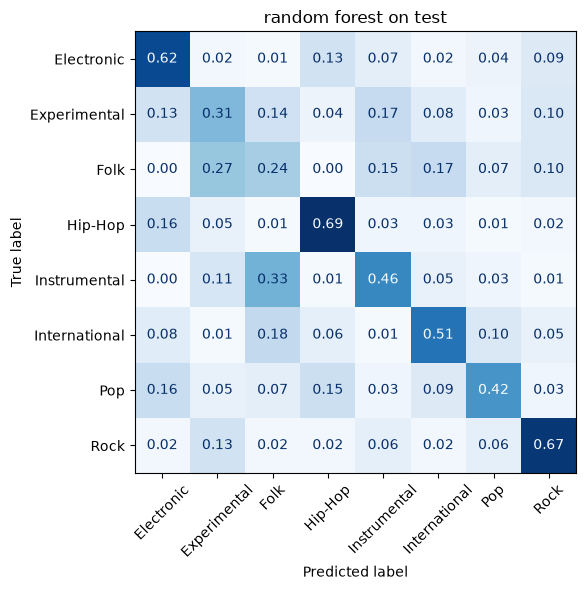

In [7]:
val = scores[scores["split"] == "validation"].set_index("model")
best = val["macro_f1"].idxmax()
pred, per_class = preds[best, "test"]
fig = plot_confusion(y_test, pred, labels=searches[best].classes_, title=f"{best.replace('_', ' ')} on test")
fig.savefig(FIGURES / "fma_baselines_confusion.png", dpi=200)
print("Best on validation:", best)
per_class.sort_values("recall_tpr")

H1 predicts Experimental, International and Pop have the lowest recall. Compare with the three lowest rows above.

## 7. Interpretation

### Decision tree, top 3 levels

Thresholds are in standardised units (z-scores), because the scaler runs before the tree.

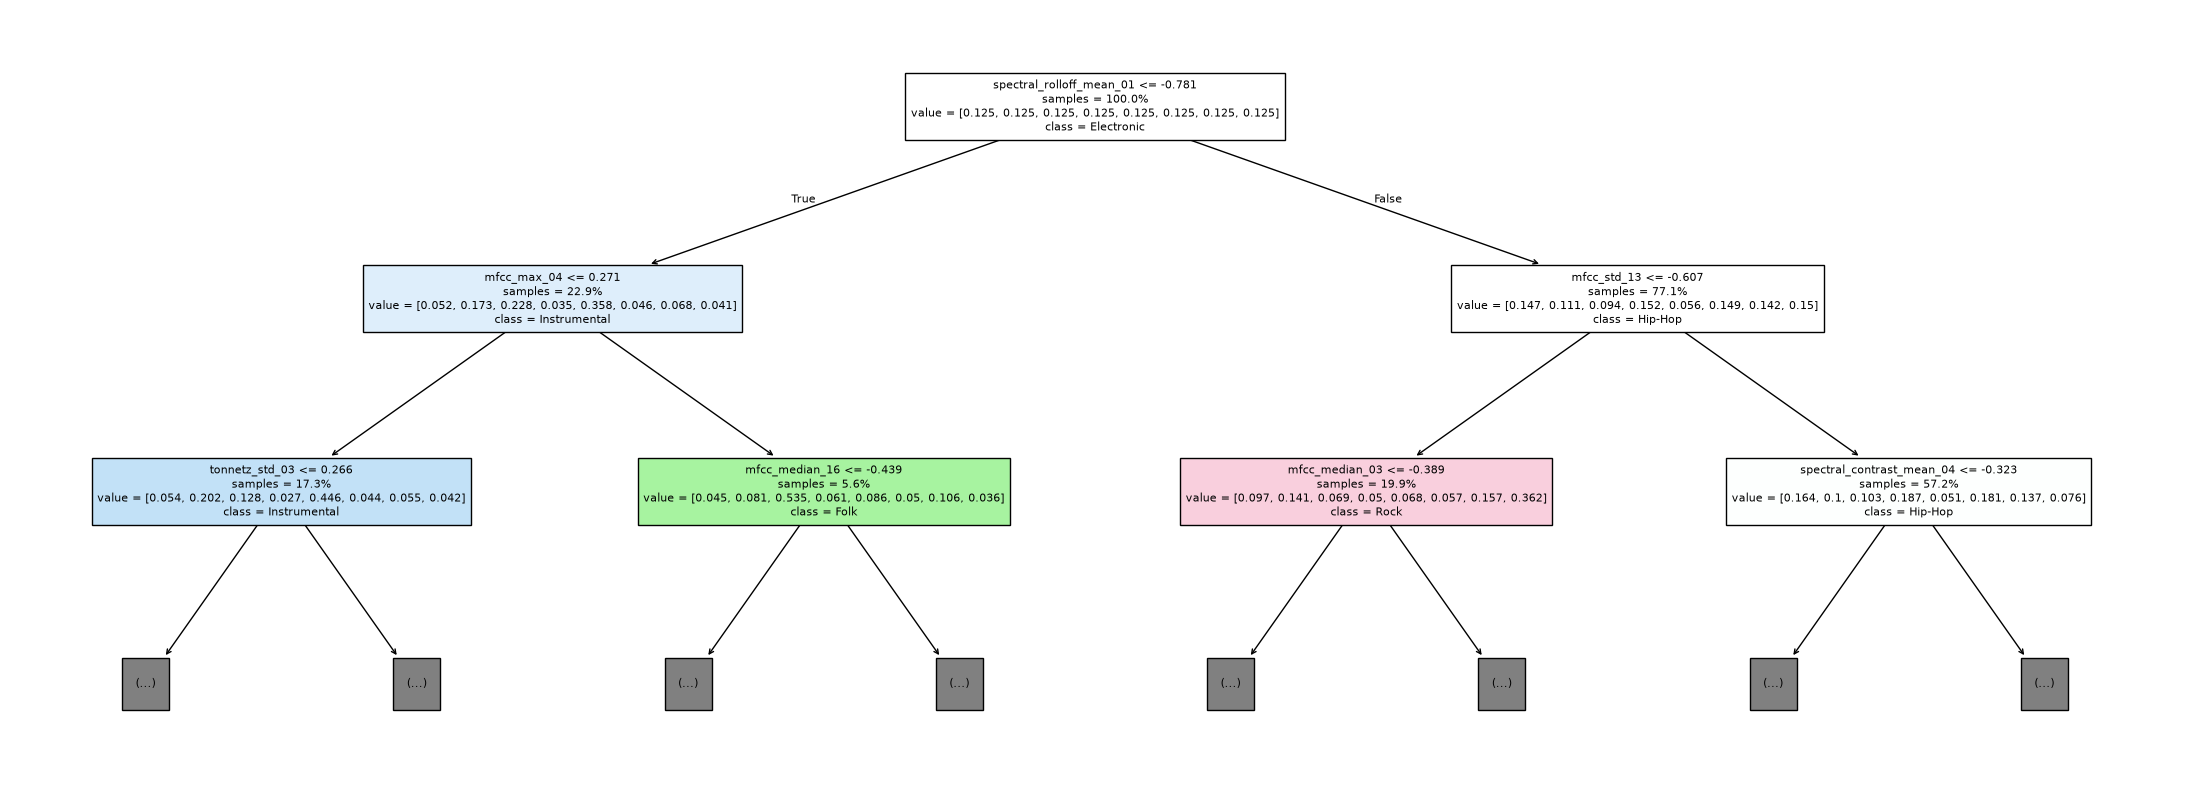

In [8]:
dt = searches["decision_tree"].best_estimator_["model"]
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(dt, max_depth=2, feature_names=list(X_train.columns), class_names=list(dt.classes_),
          filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "fma_dt_top_levels.png", dpi=200)

### Random forest feature importance by feature group (RQ4)

,total,per_feature,features
mfcc,0.3407,0.0024,140
spectral_contrast,0.1392,0.0028,49
chroma_stft,0.1178,0.0014,84
chroma_cens,0.1098,0.0013,84
chroma_cqt,0.1013,0.0012,84
tonnetz,0.0797,0.0019,42
spectral_rolloff,0.0255,0.0036,7
spectral_centroid,0.0245,0.0035,7
spectral_bandwidth,0.0226,0.0032,7
rmse,0.0207,0.0030,7


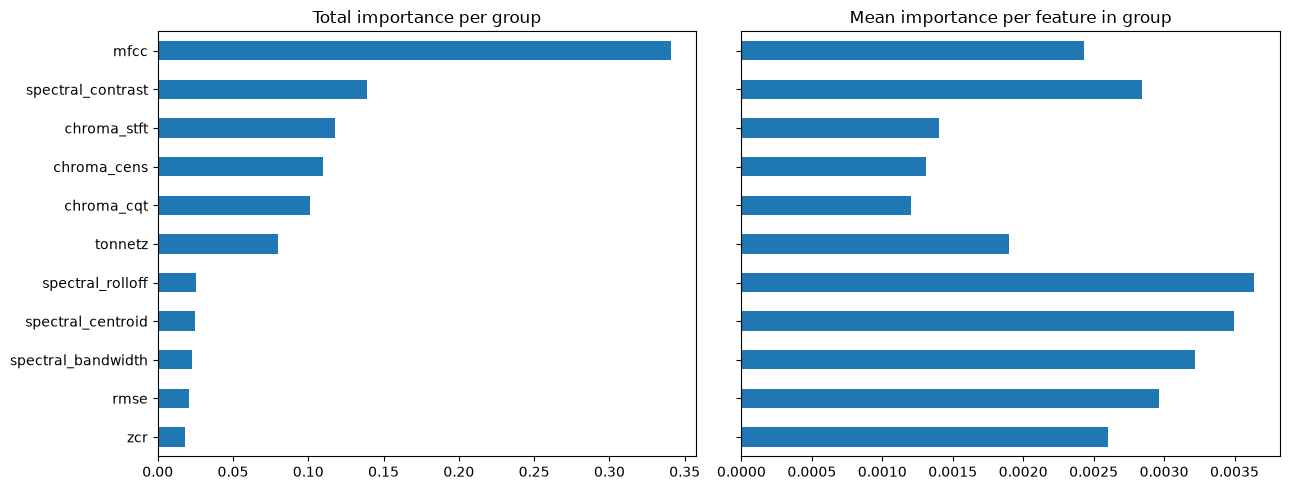

In [9]:
rf = searches["random_forest"].best_estimator_["model"]
group = pd.Series(["_".join(c.split("_")[:-2]) for c in X_train.columns])  # mfcc_mean_01 -> mfcc
# Impurity-based importance sums to 1 over all 518 features. The total shows a group's overall
# contribution; the per-feature mean corrects for group size (mfcc has 140 columns, centroid 7).
imp = pd.Series(rf.feature_importances_).groupby(group).agg(total="sum", per_feature="mean",
                                                            features="size").sort_values("total")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
imp["total"].plot.barh(ax=a1, title="Total importance per group")
imp["per_feature"].plot.barh(ax=a2, title="Mean importance per feature in group")
fig.tight_layout()
fig.savefig(FIGURES / "fma_rf_group_importance.png", dpi=200)
imp.sort_values("total", ascending=False).round(4)

## 8. Decision trees, KNN and Naive Bayes in music classification

**Decision tree.** Used where a classifier must be explained, such as auditing why a streaming service tagged a track, because each prediction is a short chain of feature thresholds. Strength: readable rules; the top split here is `spectral_rolloff_mean_01`, a spectral descriptor. Weakness: high variance. It reached 0.3598 test macro-F1, 0.1269 below the random forest that averages many trees, and its training score in the validation curve sits well above CV.

**KNN.** Used for content-based recommendation and "find songs like this", where the neighbours themselves are the output. Strength: no training and no assumptions about class shape. Weakness: with 518 standardised features, distances concentrate and redundant groups (MFCC, chroma) dominate. It reached 0.2938 test macro-F1 with k = 3 and distance weighting, and every prediction scans all 6,400 training tracks.

**Naive Bayes.** Used as a fast first-pass tagger on large catalogues, since it trains in one pass and gives probabilities. Strength: fastest model here (0.2 s to refit). Weakness: assumes features are independent within a genre, which Phase 1 contradicts (165 pairs with |r| > 0.9). It scored 0.3494 test macro-F1.

## Findings

- Random forest was the best model on validation (0.5389 macro-F1). On test it reached 0.4867 macro-F1, 0.4175 MCC and 0.8280 macro-AUC, compared with ZeroR at 0.0278 macro-F1, 0.0000 MCC and 0.5000 macro-AUC.
- Chosen hyperparameters were 300 trees, no depth limit and `max_features="sqrt"`. The random forest fits the training data almost perfectly (≈1.0 vs 0.56 CV), but averaging 300 trees still gives the best CV score of the tree models, while the decision tree's training score is substantially above CV and the logistic-regression training score rises as C grows while CV peaks at C = 0.01. KNN's training curve reaches 1.0 because distance weighting makes each training track its own nearest neighbour.
- The lowest recalls for the random forest are Folk (0.24), Experimental (0.31) and Pop (0.42). H1 is only partly supported: Experimental and Pop match the hypothesis, but Folk replaces International (0.51) in the bottom three.
- The largest confusions are Instrumental as Folk (33%) and Folk as Experimental (27%), then Folk as International (17%) and Experimental as Instrumental (17%). Hip-Hop and Electronic are confused both ways (16% and 13%), and Pop is spread across Electronic (16%) and Hip-Hop (15%). The acoustic genres (Folk, Instrumental, Experimental) form one confused block and the beat-driven genres (Electronic, Hip-Hop, Pop) another.
- MFCC is the most important group in total (0.3407). At per-feature level, spectral rolloff (0.0036), spectral centroid (0.0035) and spectral bandwidth (0.0032) are highest, so both total and mean importance are needed for RQ4.
- Naive Bayes is fastest (0.2 s refit) but has lower test macro-F1 (0.3494). Logistic regression takes 39.5 s and reaches 0.4494, while random forest takes 26.9 s and gives the best test macro-F1 (0.4867). The test scores are 0.05-0.13 below validation; for example, random forest falls from 0.5389 to 0.4867. A likely limitation is the official artist-preserving split, which may keep unfamiliar artists in test.